In [1]:
import dafeaero as da

c:\Users\hp\OneDrive\Рабочий стол\Morphing_Wing_Instrument\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Набор профилей сформирован
8
Запуск оптимизации перебором.


Поток 1: 100%|██████████| 4/4 [05:59<00:00, 89.84s/шт]


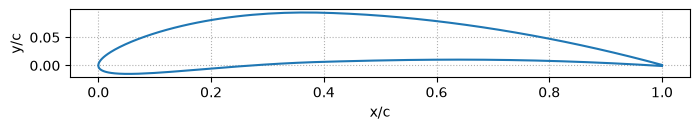

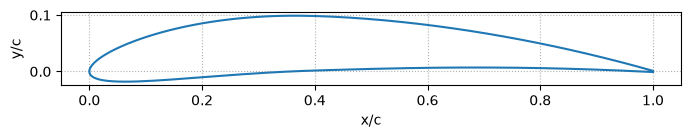

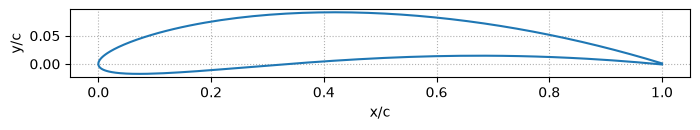

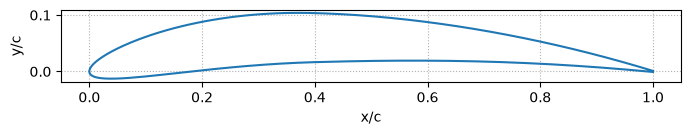

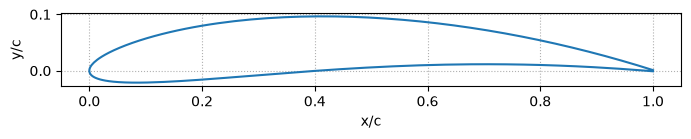

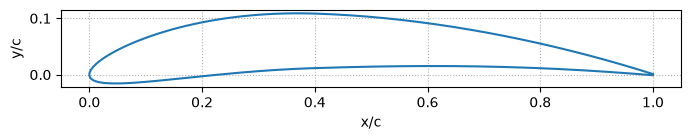

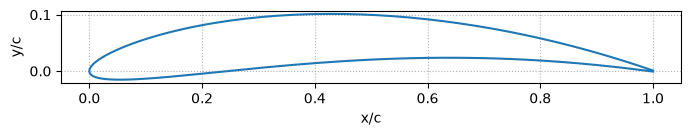

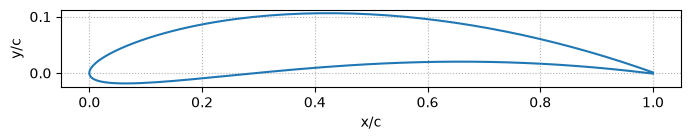

Оптимизация перебором завершена.


In [2]:
from itertools import product
from pathlib import Path

def generate_airfoil(a, b, c):
    return da.Airfoil.naca(f"{a}{b}{c:02d}")


flap_settings = da.optimization.OptimizationFlapSettings(
    da.ParameterSequence(5, 35, 10),
    da.ParameterSequence(0.75),
)

settings = da.optimization.MinCruiseDragOptSettings(
    v_stall=9,
    v_cruise=14,
    mass=5,
    aspect_ratio=9,
    oswald_efficiency=0.85,
    flap_settings=flap_settings,
)


# Пространство перебора:
# a = 0..7
# b = 1..8
# c = 6..15
a_values = range(5, 7)
b_values = range(4, 6)
c_values = da.ParameterSequence(9, 10).values()

airfoils = [
    generate_airfoil(a, b, c)
    for a, b, c in product(a_values, b_values, c_values)
]
print("Набор профилей сформирован")
print(len(airfoils))

# Запуск полного перебора
result = da.optimization.launch_exhaustive_optimization(
    airfoil_sequence=airfoils,
    objective_function=da.optimization.ObjectiveFunction.MIN_CRUISE_DRAG,
    optimization_settings=settings,
    threads=2,
    report_path=Path("reports") / "exhaustive_naca.pdf",
)


In [ ]:
from itertools import product
from pathlib import Path

def generate_airfoil(a, b, c):
    return da.Airfoil.naca(f"{a}{b}{c:02d}")


flap_settings = da.optimization.OptimizationFlapSettings(
    da.ParameterSequence(5, 35, 5),
    da.ParameterSequence(0.75),
)

settings = da.optimization.MinCruiseDragOptSettings(
    v_stall=9,
    v_cruise=14,
    mass=5,
    aspect_ratio=9,
    oswald_efficiency=0.85,
    flap_settings=flap_settings,
)


# Пространство перебора:
# a = 0..7
# b = 1..8
# c = 6..15
a_values = range(0, 8)
b_values = range(1, 9)
c_values = da.ParameterSequence(6, 15).values()

airfoils = [
    generate_airfoil(a, b, c)
    for a, b, c in product(a_values, b_values, c_values)
]
print("Набор профилей сформирован")

# Запуск полного перебора
result = da.optimization.launch_exhaustive_optimization(
    airfoil_sequence=airfoils,
    objective_function=da.optimization.ObjectiveFunction.MIN_CRUISE_DRAG,
    optimization_settings=settings,
    threads=7,
    report_path=Path("reports") / "exhaustive_naca.pdf",
)


best_airfoil = result["airfoil"]
best_drag_X = result["drag_X"]
report = result["report"]

Набор профилей сформирован
Запуск оптимизации перебором.


Перебор профилей:   7%|▋         | 44/640 [8:58:16<121:31:04, 734.00s/шт] 


KeyboardInterrupt: 